# **Analysis of the dataset "📚 Students Performance Dataset 📚 by Rabie El Kharoua" for the prdeictive model "Student's Performance Prediction"**

Importing libraries

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Reading and understanding the data

In [27]:
df = pd.read_csv('../data/Student_performance_data.csv')
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


In [14]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


In [15]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='str')

In [16]:
df.shape

(2392, 15)

In [17]:
df.isnull().sum()

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

Dropping unnecessary columns

In [19]:
df_target = df.copy()
df_target = df.drop(columns=['StudentID','GradeClass'])
print(df_target.head)

<bound method NDFrame.head of       Age  Gender  Ethnicity  ParentalEducation  StudyTimeWeekly  Absences  \
0      17       1          0                  2        19.833723         7   
1      18       0          0                  1        15.408756         0   
2      15       0          2                  3         4.210570        26   
3      17       1          0                  3        10.028829        14   
4      17       1          0                  2         4.672495        17   
...   ...     ...        ...                ...              ...       ...   
2387   18       1          0                  3        10.680555         2   
2388   17       0          0                  1         7.583217         4   
2389   16       1          0                  2         6.805500        20   
2390   16       1          1                  0        12.416653        17   
2391   16       1          0                  2        17.819907        13   

      Tutoring  ParentalSupport  

Dividing the attributes into numerical and categorical

In [20]:
numerical_columns = [col for col in df_target.columns if df_target[col].nunique() > 5]
categorical_columns = df_target.columns.difference(numerical_columns).difference(['GradeClass']).to_list()

print(numerical_columns)
print(categorical_columns)

['StudyTimeWeekly', 'Absences', 'GPA']
['Age', 'Ethnicity', 'Extracurricular', 'Gender', 'Music', 'ParentalEducation', 'ParentalSupport', 'Sports', 'Tutoring', 'Volunteering']


**Overview:**

    Dataset Shape: (2392, 13)
    Null Values: None
    Duplicate Values: None
    Target Variable: GPA
    Dropped Column: GradeClass, StudentID

df_target -- new dataset which is the target variables of the model, that doesn't include unnecessary columns ID and GradeClass

# Exploratory Data Analysis

Analysing each type of data, for both categorical and numerical values

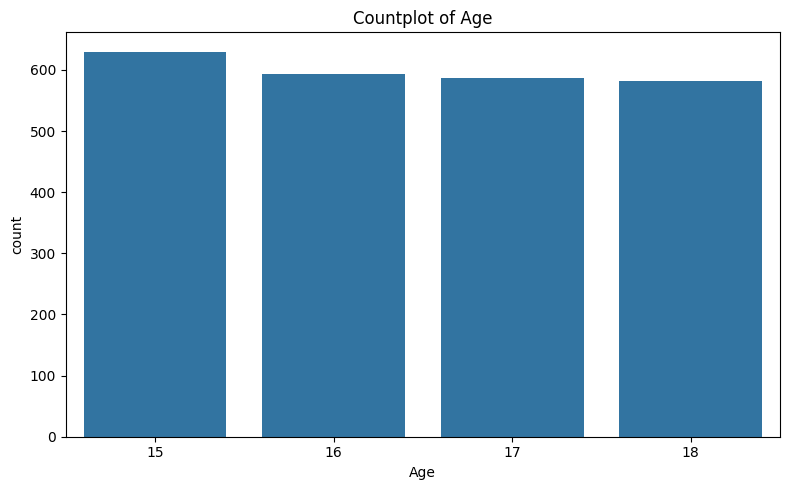

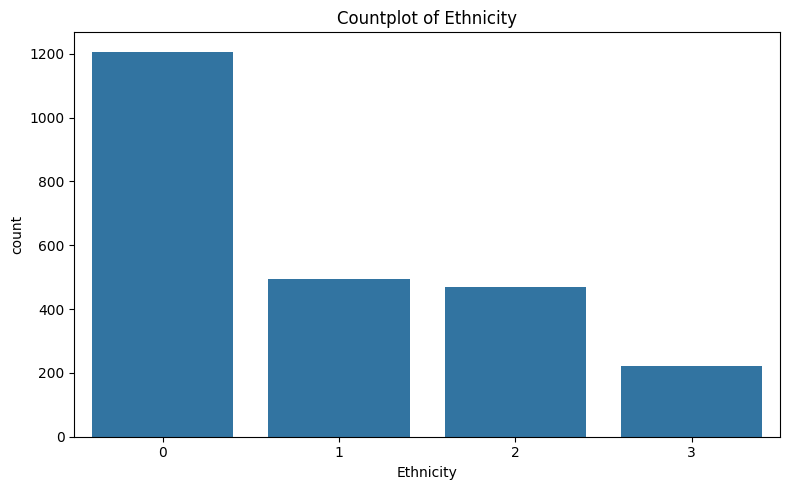

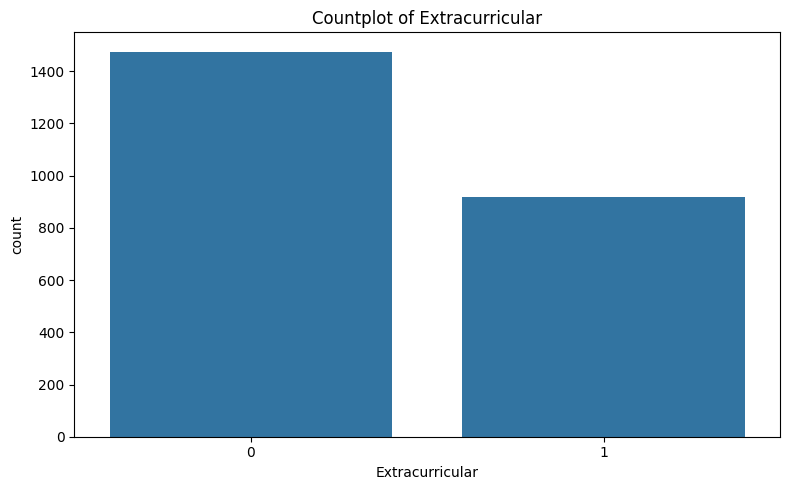

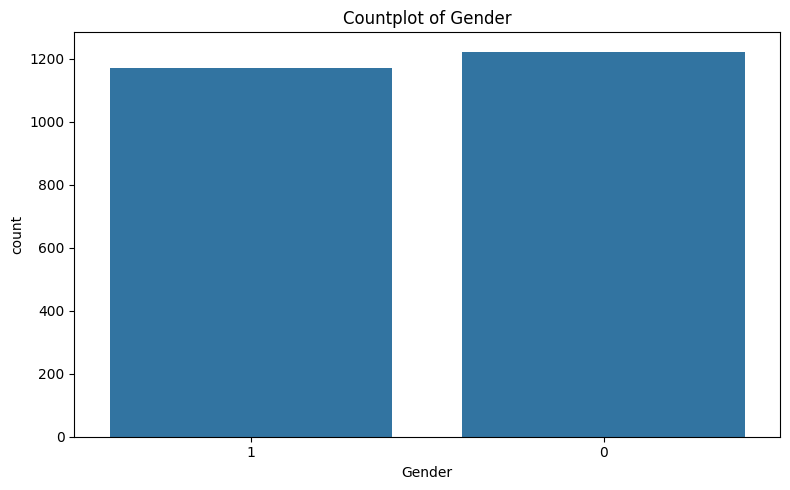

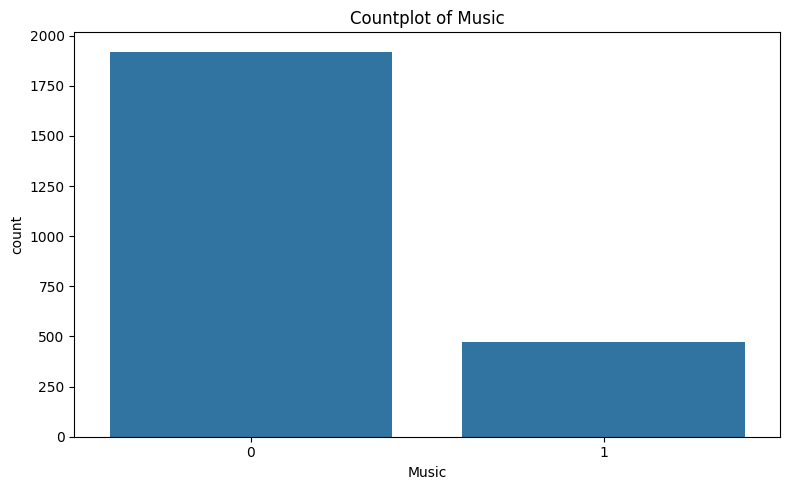

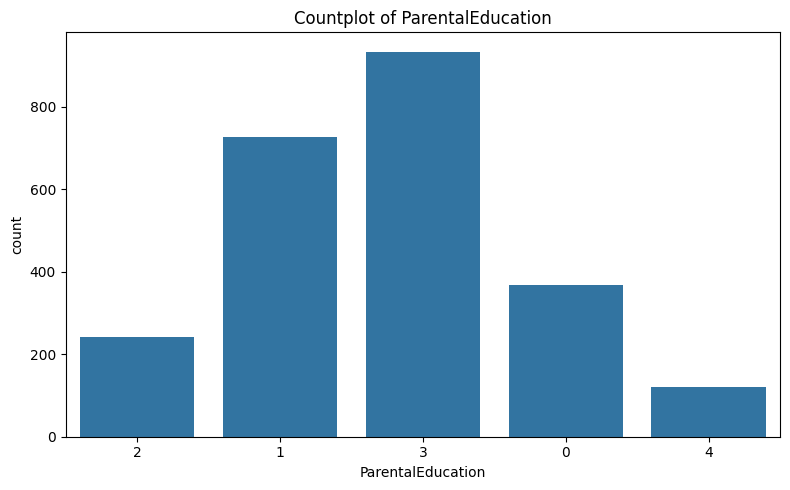

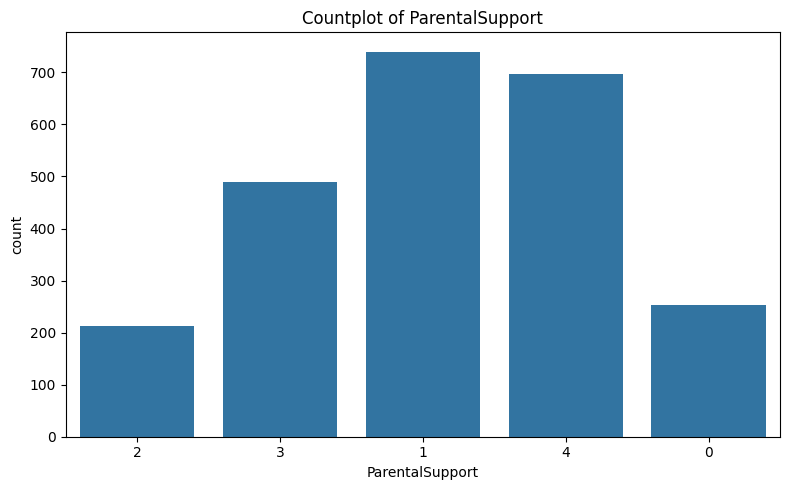

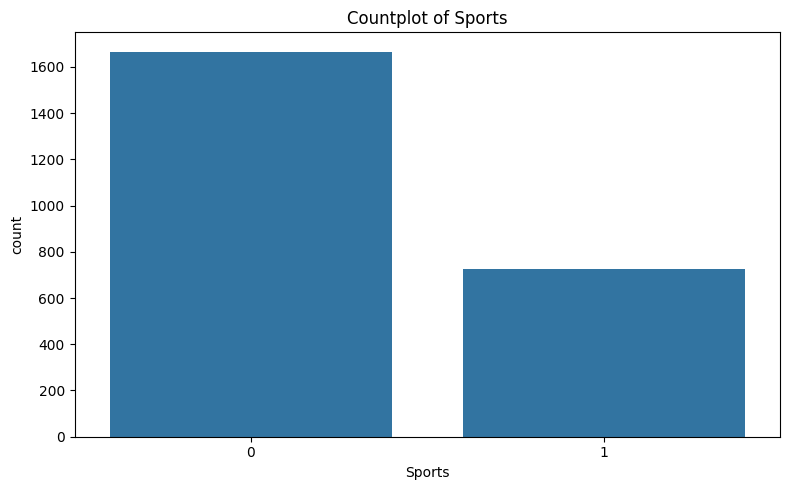

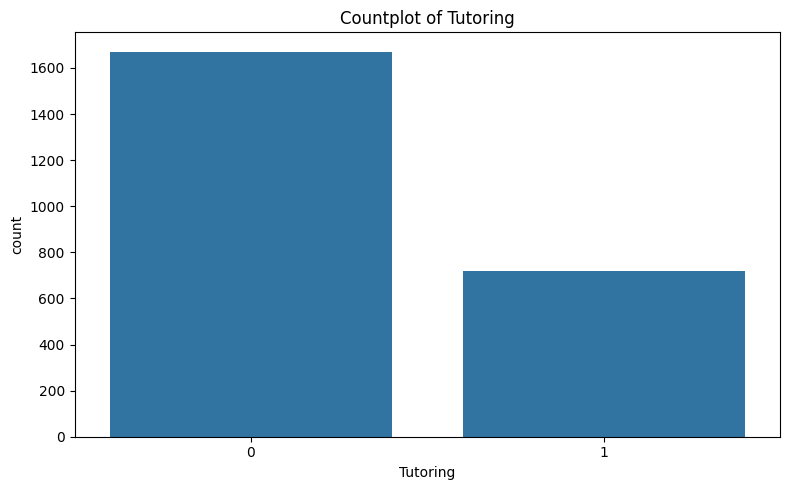

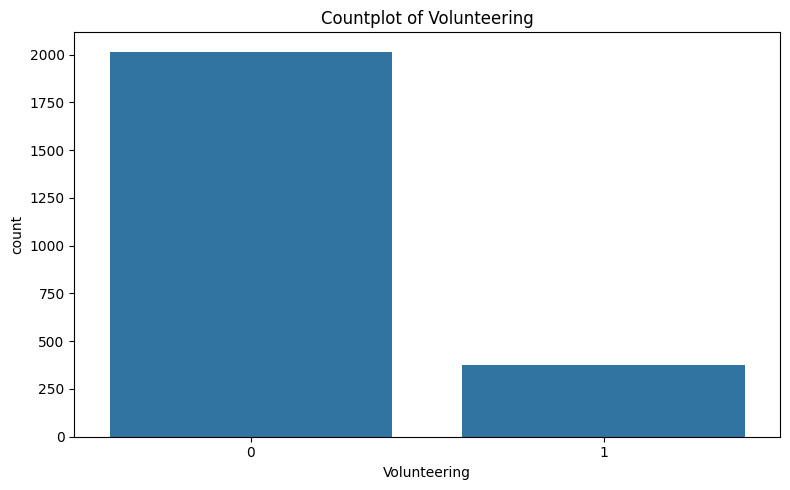

In [21]:
for column in categorical_columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df_target, x=column)
    plt.title(f'Countplot of {column}')

    labels = df_target[column].value_counts().index.tolist()
    counts = df_target[column].value_counts().tolist()
    ticks = range(len(labels))
    plt.xticks(ticks=ticks, labels=labels)

    plt.tight_layout()
    plt.show()

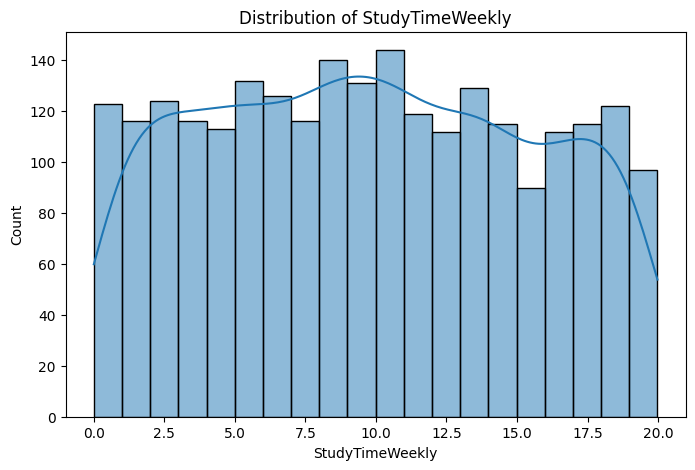

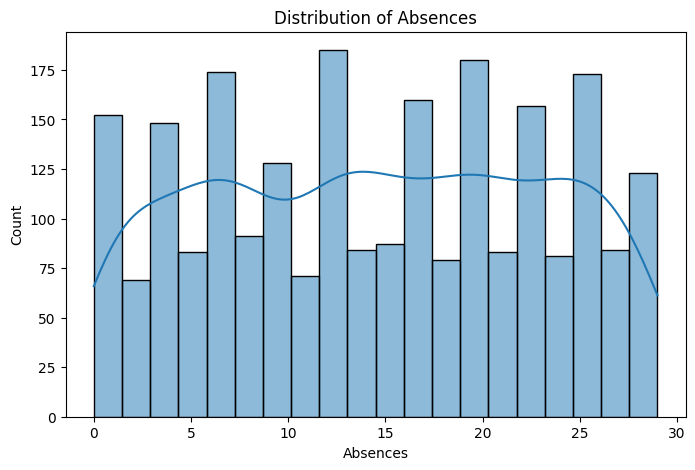

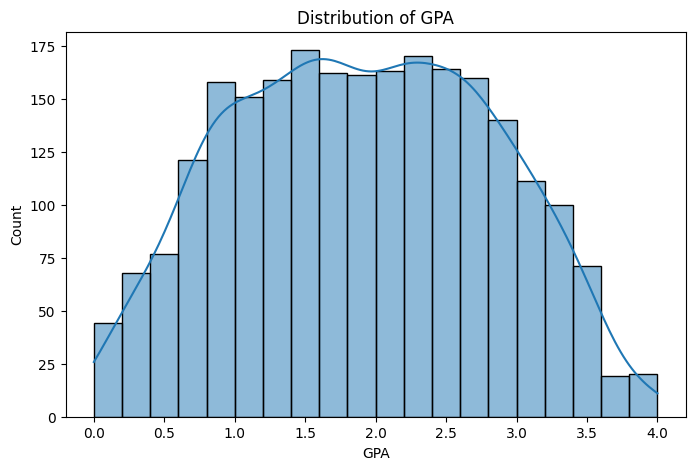

In [22]:
# numerical columns
for column in numerical_columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df_target, x=column, kde=True, bins=20)
    plt.title(f'Distribution of {column}')
    plt.show()

Heatmap of correlations

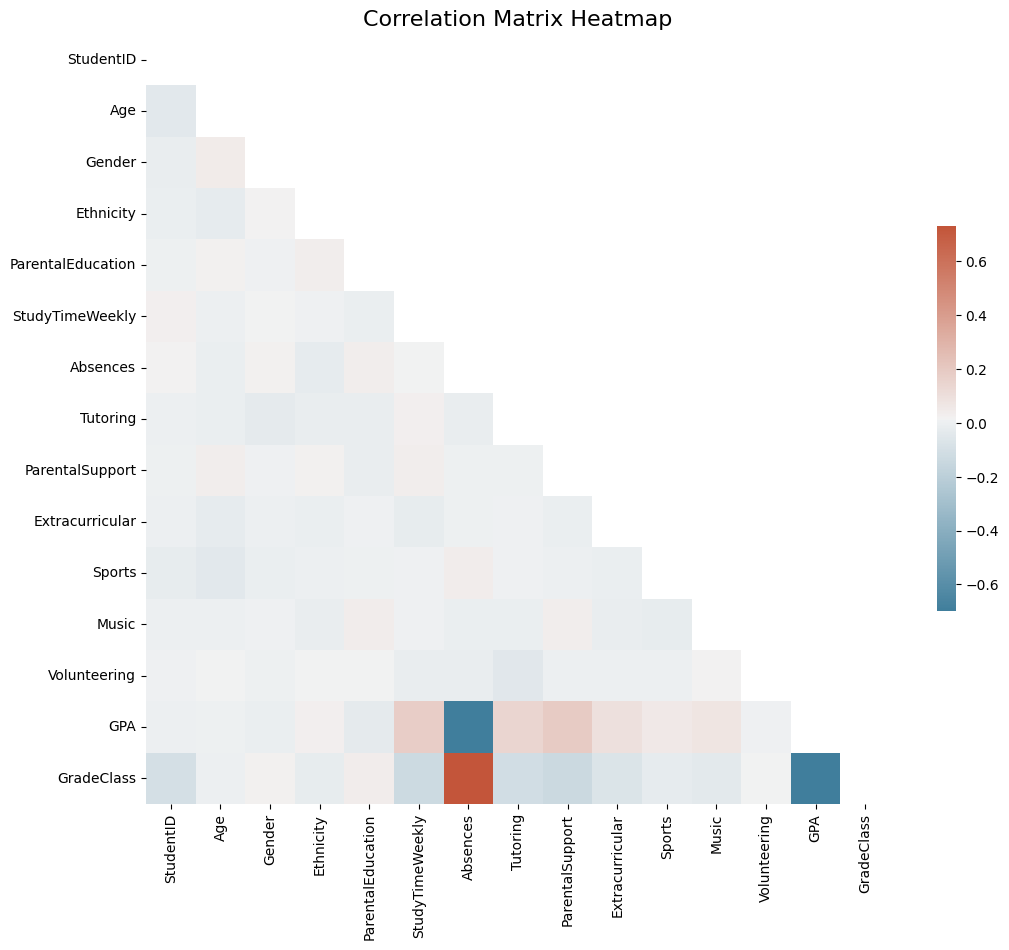

In [23]:
mask = np.triu(np.ones_like(df.corr(), dtype=bool))

cmap = sns.diverging_palette(230, 20, as_cmap=True)

plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(),cmap=cmap, cbar_kws={"shrink": .5}, vmin=-0.7, mask=mask)
plt.title('Correlation Matrix Heatmap', fontsize=16)

plt.show()

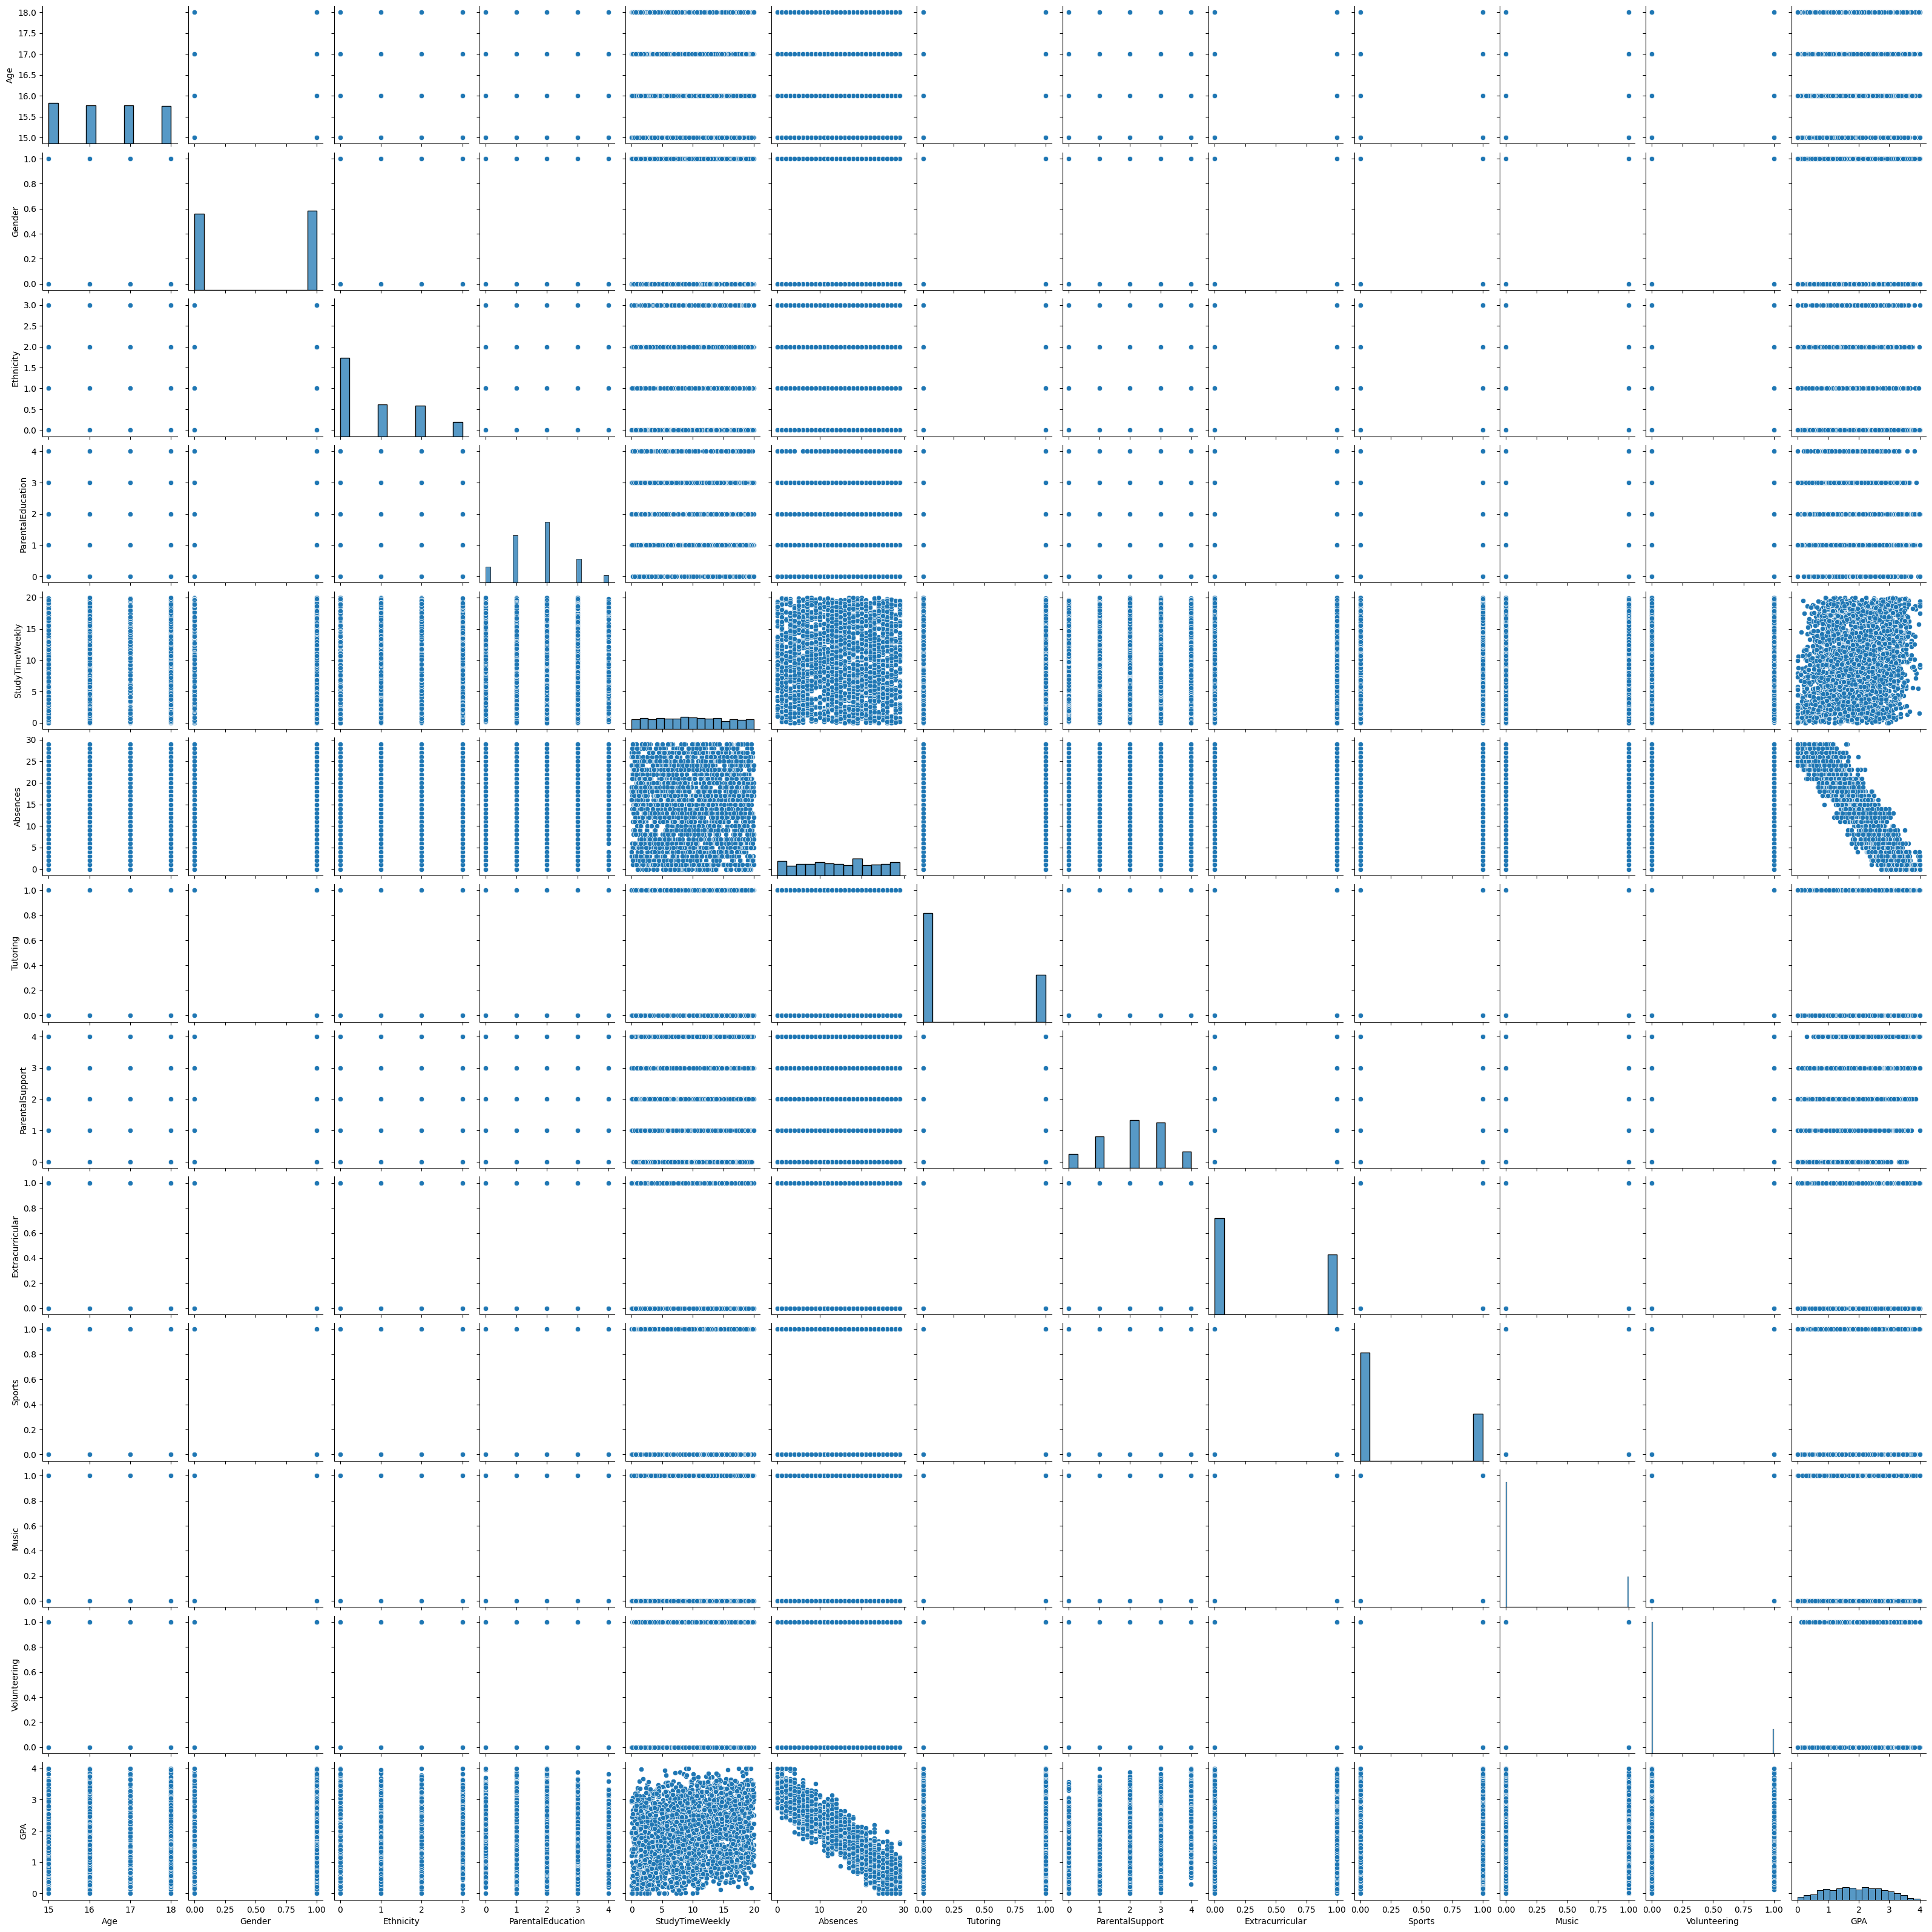

In [24]:
sns.pairplot(df_target)

Absences has the highest correlation with the target variable (GPA)

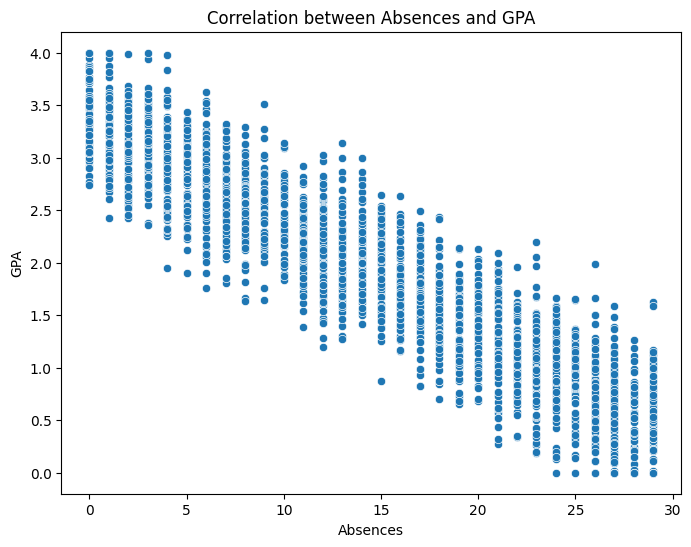

In [25]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Absences', y='GPA', data=df_target)
plt.title('Correlation between Absences and GPA')
plt.xlabel('Absences')
plt.ylabel('GPA')

plt.show()

Distribution of the target variable

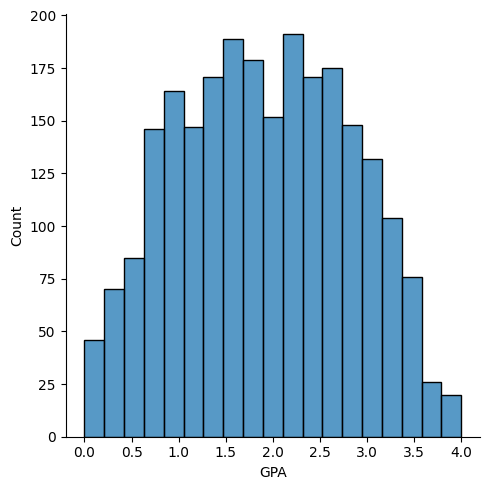

In [26]:
sns.displot(df_target['GPA'])